Validation images found: 200
Model exists: True
Testing image: 000098.jpg

image 1/1 c:\Users\yatha\Desktop\autonomous-driving-perception\data\kitti_yolo\images\val\000098.jpg: 128x416 4 cars, 24.0ms
Speed: 190.3ms preprocess, 24.0ms inference, 94.1ms postprocess per image at shape (1, 3, 128, 416)
Results saved to C:\Users\yatha\Desktop\autonomous-driving-perception\runs\baseline_predictions


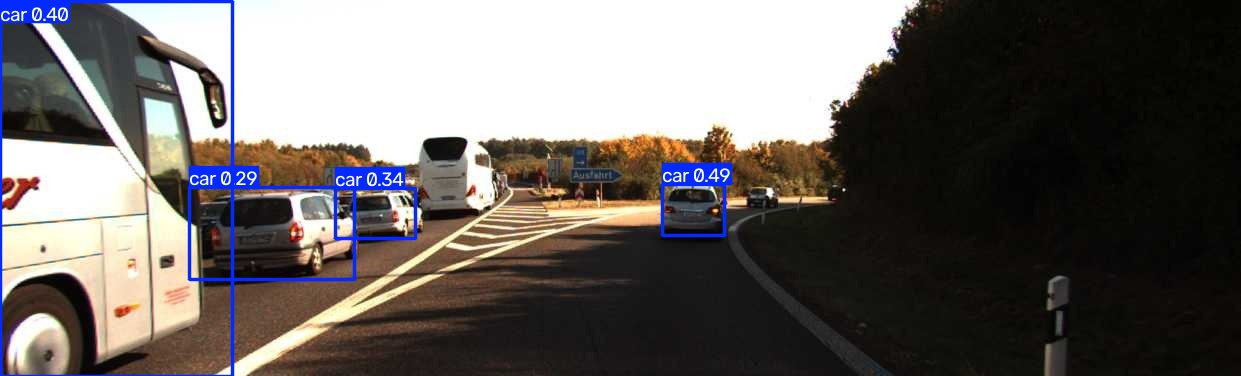

Prediction saved to: C:\Users\yatha\Desktop\autonomous-driving-perception\runs\baseline_predictions\000098.jpg


In [2]:
from pathlib import Path
from ultralytics import YOLO
from IPython.display import Image, display

project_dir = Path.cwd().parent

model_path = (
    project_dir / "runs" / "kitti_smoke_test"
    / "weights" / "best.pt"
)

val_dir = project_dir / "data" / "kitti_yolo" / "images" / "val"

# Find an image that actually exists
val_images = sorted(
    p for p in val_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

print("Validation images found:", len(val_images))
print("Model exists:", model_path.exists())

assert model_path.exists(), f"Model not found: {model_path}"
assert val_images, f"No images found in: {val_dir}"

image_path = val_images[0]
print("Testing image:", image_path.name)

model = YOLO(str(model_path))

results = model.predict(
    source=str(image_path),
    imgsz=416,
    conf=0.25,
    device=0,
    save=True,
    project=str(project_dir / "runs"),
    name="baseline_predictions",
    exist_ok=True
)

# Display the annotated prediction
output_path = Path(results[0].save_dir) / image_path.name
display(Image(filename=str(output_path)))

print("Prediction saved to:", output_path)

In [5]:

from pathlib import Path
from ultralytics import YOLO
import torch

project_dir = Path.cwd().parent
data_yaml = project_dir / "data" / "kitti.yaml"

print("CUDA available:", torch.cuda.is_available())
print("Dataset YAML exists:", data_yaml.exists())

model = YOLO("yolo11n.pt")

results = model.train(
    data=str(data_yaml),
    epochs=50,
    imgsz=416,
    batch=4,
    device=0,
    workers=2,
    project=str(project_dir / "runs"),
    name="kitti_improved",
    exist_ok=True,
    patience=7,
    seed=42,
    plots=True
)


CUDA available: True
Dataset YAML exists: True
Ultralytics 8.4.184  Python-3.11.9 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\yatha\Desktop\autonomous-driving-perception\data\kitti.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937